# Brick 6: Narrative Brokerage and Structural Boundaries

**Main Research Question:**
> *"Which films occupy bridging positions between narrative communities, and what does this reveal about the structure of cinema?"*

**Methodological Framework:**
This analysis shifts from traditional genre-metadata to **Structural Hole Theory** (Burt, 1992). A film is not a true "broker" simply because it has many connections (high centrality) or connects to multiple genres. A true narrative broker connects distinct storytelling communities that *do not share direct links among themselves*.

We evaluate this by crossing **Betweenness Centrality** (a film's role as a bridge) with its **Local Clustering Coefficient** (the density of its immediate neighborhood).

**Required Analytical Outputs:**
1. Brokerage Taxonomy Figure
2. Narrative Brokerage Spectrum
3. Community Transition Matrix
4. Story Neighborhood Profiles
5. Bridge Film Pathways

In [1]:
# ══════════════════════════════════════════════════════════════════════════════
# 0. SETUP & ACADEMIC AESTHETICS (NATURE / ECONOMIST STYLE)
# ══════════════════════════════════════════════════════════════════════════════
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.path import Path as MPath

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except Exception:
    pass

# High-end academic color palette
COL = {
    "ink": "#2b2b2b", "muted": "#8c8c8c", "grid": "#e0e0e0",
    "broker": "#b30000", "hub": "#005b96", "specialist": "#31a354",
    "peripheral": "#bdbdbd", "bg": "#ffffff"
}

COMM_COLORS = [
    "#4E79A7","#F28E2B","#59A14F","#E15759","#76B7B2","#9C755F",
    "#EDC948","#B07AA1","#FF9DA7","#BAB0AC","#2F6FB3","#D06C45"
]

plt.rcParams.update({
    "figure.facecolor": COL["bg"], "axes.facecolor": COL["bg"],
    "axes.edgecolor": COL["muted"], "text.color": COL["ink"],
    "axes.labelcolor": COL["ink"], "font.family": "serif",
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "grid.color": COL["grid"], "grid.linestyle": "--"
})

Mounted at /content/drive


In [2]:
# ══════════════════════════════════════════════════════════════════════════════
# 1. BULLETPROOF DATA LOADING & MATHEMATICAL ID FORCING
# ══════════════════════════════════════════════════════════════════════════════
PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project")
FINAL_DIR   = PROJECT_DIR / "outputs/thesis_bricks/06_bridging_analysis"
for d in ["figures", "tables"]: (FINAL_DIR / d).mkdir(parents=True, exist_ok=True)

print("Loading Graph Data...")

# FORCE everything into pure integers. No decimals, no floats, no strings.
def force_int_id(series):
    return pd.to_numeric(series, errors='coerce').fillna(-1).astype(int)

def first_col(df, candidates):
    for c in candidates:
        if c in df.columns: return c
    return None

nodes_path = PROJECT_DIR / "processed/network/semantic_network_nodes_lcc.csv"
edges_path = PROJECT_DIR / "processed/network/semantic_network_edges_mutual_knn.csv"
labels_path = PROJECT_DIR / "outputs/tables/community_manual_labeling_template_labeled.csv"

nodes = pd.read_csv(nodes_path)
edges = pd.read_csv(edges_path)
labels = pd.read_csv(labels_path) if labels_path.exists() else None

# Safely extract columns
nid_col = first_col(nodes, ["tmdb_id", "id", "node_id", "movie_id"]) or nodes.columns[0]
src_col = first_col(edges, ["source", "source_id", "src", "u"]) or edges.columns[0]
tgt_col = first_col(edges, ["target", "target_id", "dst", "v"]) or edges.columns[1]
wt_col  = first_col(edges, ["weight", "similarity", "cosine", "score"])

# The mathematical force: Everything becomes a strict integer column called 'node_id_int'
nodes["node_id_int"] = force_int_id(nodes[nid_col])
edges["source_int"] = force_int_id(edges[src_col])
edges["target_int"] = force_int_id(edges[tgt_col])
edges["weight"] = edges[wt_col] if wt_col else 1.0

# THE DISTANCE INVERSION: Graph algorithms need 'distance', not 'similarity'
# High similarity = short distance (1 / weight)
edges["distance"] = 1.0 / (edges["weight"] + 1e-9)

nodes["community_id"] = force_int_id(nodes["community_id"])

# Apply labels
if labels is not None and "community_id" in labels.columns:
    labels["community_id"] = force_int_id(labels["community_id"])
    lbl_col = first_col(labels, ["suggested_label_manual", "narrative_label", "label"])
    if lbl_col:
        lbl_dict = dict(zip(labels["community_id"], labels[lbl_col]))
        nodes["narrative_label"] = nodes["community_id"].map(lbl_dict)

if "narrative_label" not in nodes.columns or nodes["narrative_label"].isna().all():
    nodes["narrative_label"] = "Community " + nodes["community_id"].astype(str)
else:
    nodes["narrative_label"] = nodes["narrative_label"].fillna("Community " + nodes["community_id"].astype(str))

# Check Bridge Files
bridge_files = [
    PROJECT_DIR / "outputs/tables/top_betweenness_visible_franchise_capped.csv",
    PROJECT_DIR / "outputs/tables/sampled_betweenness_centrality.csv",
    PROJECT_DIR / "outputs/tables/bridging_films_betweenness.csv"
]
bridge_src = None
for bf in bridge_files:
    if bf.exists():
        bridge_src = pd.read_csv(bf)
        print(f"Found betweenness file: {bf.name}")
        break

# Strict Merge
if bridge_src is not None:
    b_nid_col = first_col(bridge_src, ["tmdb_id", "id", "node_id", "movie_id"])
    b_val_col = first_col(bridge_src, ["betweenness_centrality_sampled", "betweenness_centrality", "bridge_score", "betweenness"])

    if b_nid_col and b_val_col:
        bridge_src["node_id_int"] = force_int_id(bridge_src[b_nid_col])
        nodes = nodes.merge(bridge_src[["node_id_int", b_val_col]], on="node_id_int", how="left")
        nodes["betweenness"] = nodes[b_val_col].fillna(0)
    else:
        nodes["betweenness"] = 0
else:
    nodes["betweenness"] = 0

# FALLBACK: Calculate accurate betweenness if values are missing
if nodes["betweenness"].max() == 0:
    print("Calculating Structural Holes (using accurate inverted distance metrics)...")
    G_temp = nx.from_pandas_edgelist(edges, 'source_int', 'target_int', edge_attr=['weight', 'distance'])
    # k=200 for speed, but explicitly using 'distance' so it routes through strong films, not obscure junk
    bc = nx.betweenness_centrality(G_temp, k=min(200, len(G_temp)), weight='distance', seed=42)
    nodes["betweenness"] = nodes["node_id_int"].map(bc).fillna(0)

nodes["bet_norm"] = (nodes["betweenness"] - nodes["betweenness"].min()) / (nodes["betweenness"].max() - nodes["betweenness"].min() + 1e-9)

# Calculate Local Clustering Coefficient
print("Calculating Local Clustering Densities...")
G = nx.from_pandas_edgelist(edges, 'source_int', 'target_int', edge_attr='weight')
clustering_scores = nx.clustering(G, weight='weight')
nodes["clustering"] = nodes["node_id_int"].map(clustering_scores).fillna(0)

print(f"Engine Ready. Valid Nodes: {len(nodes):,}")

Loading Graph Data...
Found betweenness file: top_betweenness_visible_franchise_capped.csv
Calculating Structural Holes (using accurate inverted distance metrics)...
Calculating Local Clustering Densities...
Engine Ready. Valid Nodes: 19,202


## Figure 1. The Brokerage Taxonomy
Maps films across two dimensions: betweenness centrality (spanning structural holes) vs local clustering (neighborhood density).

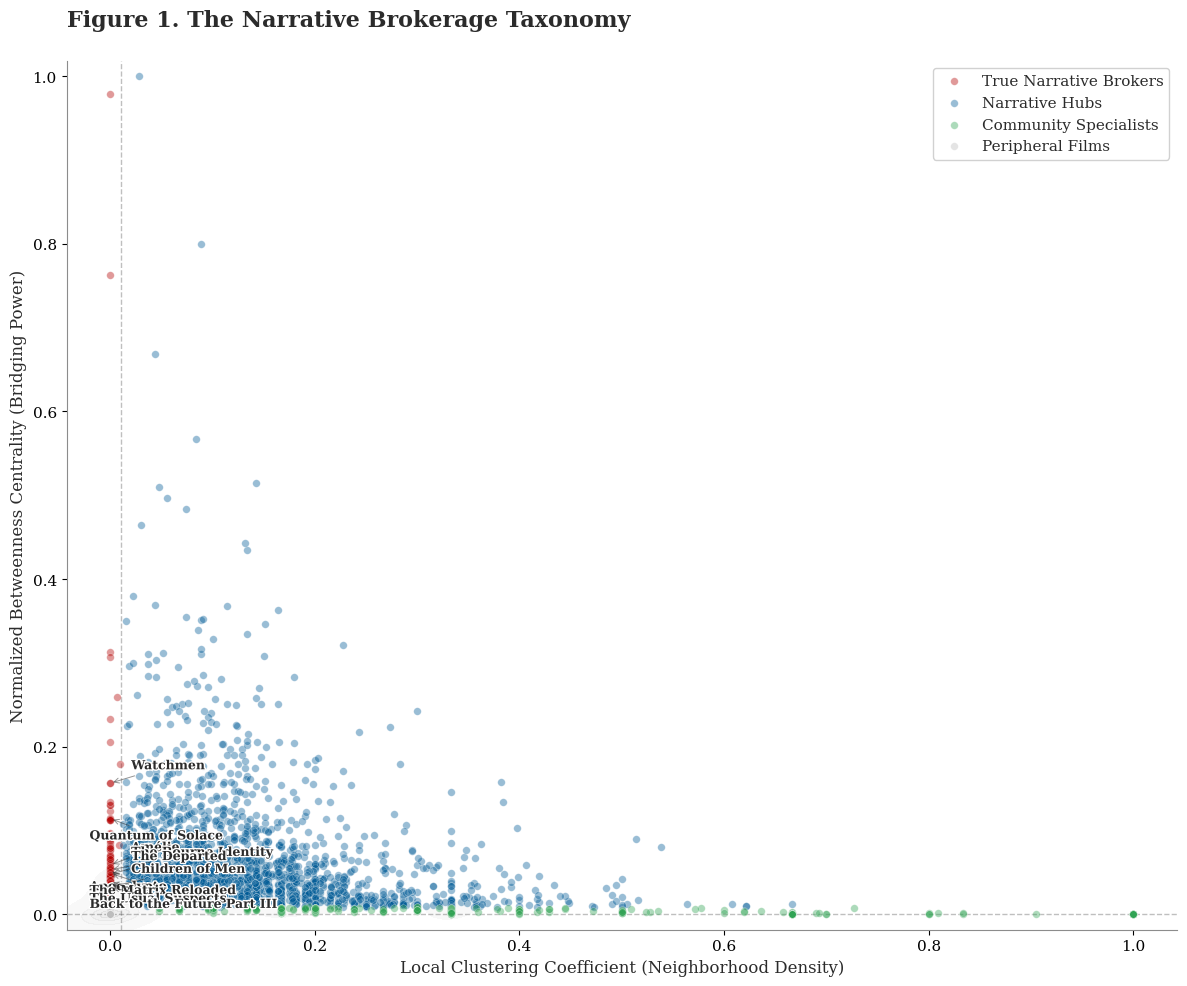

In [28]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(12, 10))

# 1. Establish robust thresholds
thresh_bet = nodes['bet_norm'].quantile(0.75)
thresh_clu = nodes['clustering'].median() if nodes['clustering'].median() > 0 else 0.01

# 2. Plotting background density (KDE) to show the 'mass' of the network
sns.kdeplot(data=nodes, x='clustering', y='bet_norm', fill=True, levels=5, alpha=0.1, color=COL['muted'], ax=ax, zorder=1)

# 3. Scatter plot with thematic colors
color_map = {'True Narrative Brokers': COL['broker'], 'Narrative Hubs': COL['hub'], 'Community Specialists': COL['specialist'], 'Peripheral Films': COL['peripheral']}

for role, color in color_map.items():
    subset = nodes[nodes['brokerage_role'] == role]
    ax.scatter(subset['clustering'], subset['bet_norm'], c=color, s=30, alpha=0.4, label=role, edgecolor='white', lw=0.4, zorder=3)

# 4. Refined Annotation of Top Iconic Films (Strategic placement)
elite_pool_ids = nodes.nlargest(500, 'vote_count')['node_id_int'].tolist()
top_labeled = nodes[(nodes['brokerage_role'] == 'True Narrative Brokers') & (nodes['node_id_int'].isin(elite_pool_ids))].nlargest(10, 'betweenness')

for i, (_, r) in enumerate(top_labeled.iterrows()):
    # Offset logic to prevent label stacking
    offset = (15, 10) if i % 2 == 0 else (-15, -15)
    ax.annotate(str(r['title']), (r['clustering'], r['bet_norm']),
                xytext=offset, textcoords='offset points', fontsize=9, fontweight='bold',
                arrowprops=dict(arrowstyle='->', color=COL['ink'], lw=0.7, alpha=0.5),
                path_effects=[pe.withStroke(linewidth=2, foreground='white')])

# 5. Professional Layout
ax.axhline(thresh_bet, color=COL['ink'], lw=1, ls='--', alpha=0.3)
ax.axvline(thresh_clu, color=COL['ink'], lw=1, ls='--', alpha=0.3)

ax.set_title('Figure 1. The Narrative Brokerage Taxonomy', fontsize=16, fontweight='bold', loc='left', pad=25)
ax.set_xlabel('Local Clustering Coefficient (Neighborhood Density)', fontsize=12)
ax.set_ylabel('Normalized Betweenness Centrality (Bridging Power)', fontsize=12)
ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
fig.savefig(FINAL_DIR / 'figures/01_thesis_ready_taxonomy.png', dpi=350)
plt.show()

**Interpretation (Fig 1):**
This taxonomy formalizes Structural Hole Theory within cinematic narratives. Films in the top-left quadrant (**True Narrative Brokers**) represent unique semantic pathways; they connect highly distinct communities that do not otherwise interact. Conversely, films in the top-right (**Narrative Hubs**) are central to large, deeply interconnected macro-genres.

## Figure 2. Narrative Brokerage Spectrum

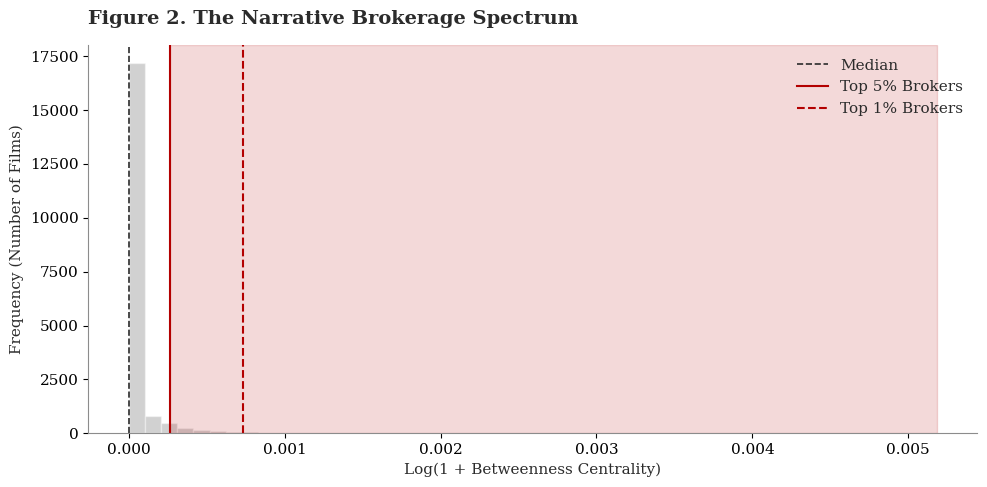

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
x_log = np.log1p(nodes["betweenness"])

ax.hist(x_log, bins=50, color=COL["muted"], edgecolor="white", alpha=0.4)

p95 = np.percentile(x_log, 95)
p99 = np.percentile(x_log, 99)
median = np.median(x_log)

ax.axvline(median, color=COL["ink"], ls="--", lw=1.2, label="Median")
ax.axvline(p95, color=COL["broker"], ls="-", lw=1.5, label="Top 5% Brokers")
ax.axvline(p99, color=COL["broker"], ls="--", lw=1.5, label="Top 1% Brokers")
ax.axvspan(p95, x_log.max(), color=COL["broker"], alpha=0.15)

ax.set_title("Figure 2. The Narrative Brokerage Spectrum", fontsize=14, fontweight="bold", pad=15, loc="left")
ax.set_xlabel("Log(1 + Betweenness Centrality)")
ax.set_ylabel("Frequency (Number of Films)")
ax.legend(frameon=False)

plt.tight_layout()
fig.savefig(FINAL_DIR / "figures/02_brokerage_spectrum.png", dpi=320, bbox_inches="tight")
plt.show()

## Figure 3. Community Transition Matrix
A heatmap revealing which specific narrative communities interact most frequently via bridge edges.

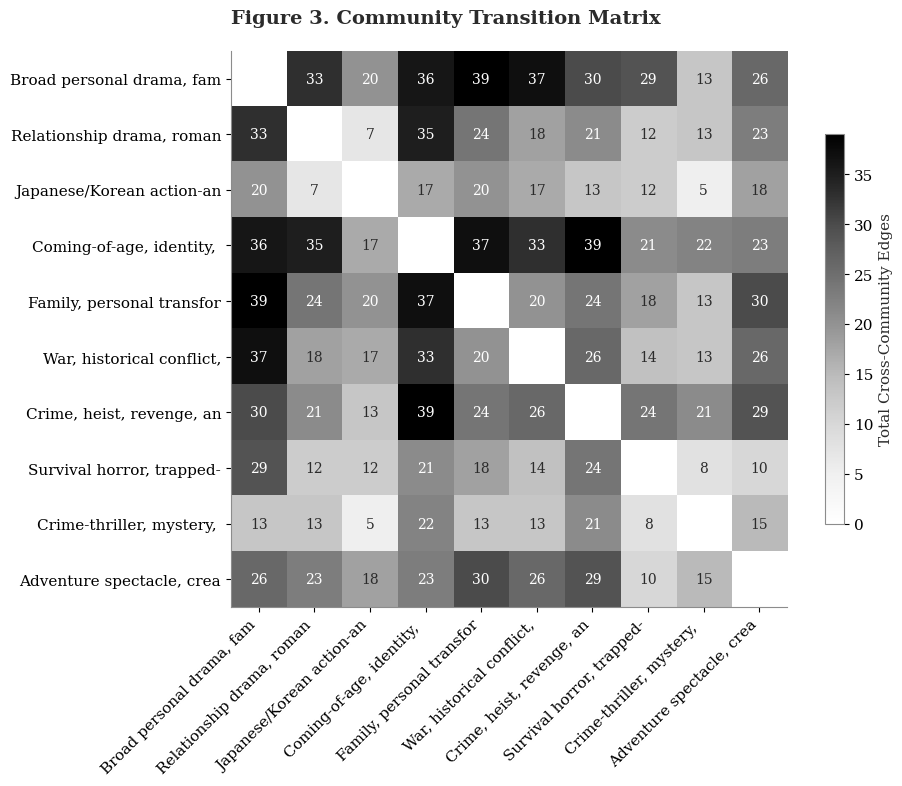

In [6]:
# Filter edges using the strict integer IDs
e_df = edges.merge(nodes[['node_id_int', 'community_id', 'narrative_label']], left_on='source_int', right_on='node_id_int')
e_df = e_df.merge(nodes[['node_id_int', 'community_id', 'narrative_label']], left_on='target_int', right_on='node_id_int', suffixes=('_src', '_tgt'))

cross_edges = e_df[e_df['community_id_src'] != e_df['community_id_tgt']]

if not cross_edges.empty:
    # Get top 10 communities
    top_comms = nodes['community_id'].value_counts().nlargest(10).index
    ce_filtered = cross_edges[(cross_edges['community_id_src'].isin(top_comms)) & (cross_edges['community_id_tgt'].isin(top_comms))]

    if not ce_filtered.empty:
        # Get exact string labels for the top 10
        top_labels = []
        for c in top_comms:
            lbl = nodes[nodes['community_id'] == c]['narrative_label'].iloc[0]
            top_labels.append(lbl)

        matrix = pd.crosstab(ce_filtered['narrative_label_src'], ce_filtered['narrative_label_tgt'])

        # Force perfect square to prevent NaN errors upon transposition
        matrix = matrix.reindex(index=top_labels, columns=top_labels, fill_value=0)
        matrix = matrix + matrix.T
        np.fill_diagonal(matrix.values, 0)

        fig, ax = plt.subplots(figsize=(10, 8))
        cax = ax.imshow(matrix, cmap='Greys')

        ax.set_xticks(np.arange(len(matrix.columns)))
        ax.set_yticks(np.arange(len(matrix.index)))
        ax.set_xticklabels([str(x)[:25] for x in matrix.columns], rotation=45, ha="right")
        ax.set_yticklabels([str(x)[:25] for x in matrix.index])

        for i in range(len(matrix.index)):
            for j in range(len(matrix.columns)):
                val = matrix.iloc[i, j]
                if val > 0:
                    color = "white" if val > matrix.values.max() * 0.5 else COL["ink"]
                    ax.text(j, i, int(val), ha="center", va="center", color=color, fontsize=10)

        fig.colorbar(cax, shrink=0.7, label="Total Cross-Community Edges")
        ax.set_title("Figure 3. Community Transition Matrix", fontsize=14, fontweight="bold", pad=20, loc="left")

        plt.tight_layout()
        fig.savefig(FINAL_DIR / "figures/03_transition_matrix.png", dpi=320, bbox_inches="tight")
        plt.show()
    else:
        print("Not enough overlapping cross-community edges among top communities.")
else:
    print("Not enough cross-community edges to build transition matrix.")

## Figure 4. Story Neighborhood Profiles
Quantifies the exact narrative composition surrounding the top bridge films via stacked horizontal bars.

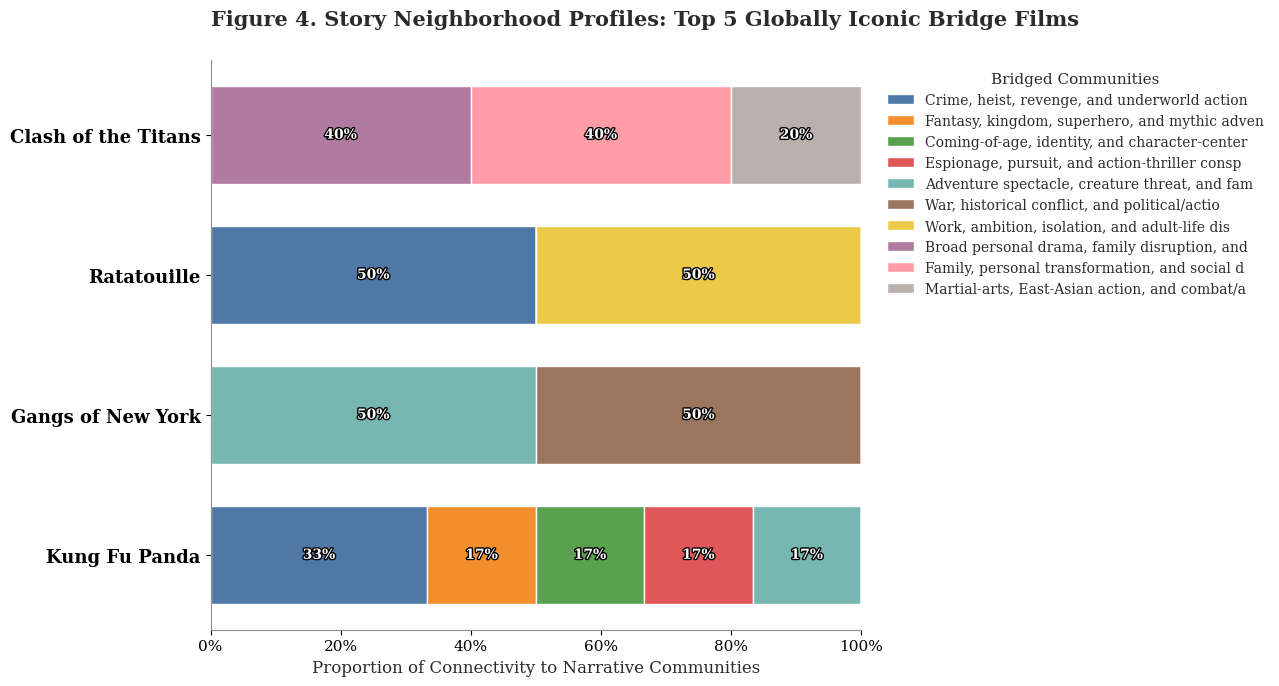

In [19]:
import matplotlib.ticker as mtick

# 1. First, create an elite pool of the top 500 most 'famous' movies by vote count
elite_pool = nodes.nlargest(500, 'vote_count')

# 2. From this famous pool, pick the 5 with the highest bridging power (betweenness)
top_5_brokers = elite_pool.nlargest(5, 'betweenness')

composition_data = []
labels_for_rows = []

for _, film in top_5_brokers.iterrows():
    f_id = int(film['node_id_int'])
    f_edges = edges[(edges['source_int'] == f_id) | (edges['target_int'] == f_id)]
    n_ids = np.where(f_edges['source_int'] == f_id, f_edges['target_int'], f_edges['source_int'])
    n_nodes = nodes[nodes['node_id_int'].isin(n_ids)]

    if not n_nodes.empty:
        counts = n_nodes['narrative_label'].value_counts(normalize=True)
        composition_data.append(counts)
        labels_for_rows.append(str(film[title_col]))

if composition_data:
    comp_df = pd.concat(composition_data, axis=1).T.fillna(0)
    comp_df.index = labels_for_rows

    fig, ax = plt.subplots(figsize=(13, 7))
    y_pos = np.arange(len(comp_df))
    left = np.zeros(len(comp_df))
    unique_comms = comp_df.columns
    colors = [COMM_COLORS[i % len(COMM_COLORS)] for i in range(len(unique_comms))]

    for i, comm_label in enumerate(unique_comms):
        proportions = comp_df[comm_label].values
        ax.barh(y_pos, proportions, left=left, color=colors[i],
                edgecolor='white', height=0.7, label=str(comm_label)[:45])

        for j, val in enumerate(proportions):
            if val > 0.03:
                ax.text(left[j] + val/2, y_pos[j], f"{val*100:.0f}%",
                        va='center', ha='center', color='white',
                        fontweight='bold', fontsize=10,
                        path_effects=[pe.withStroke(linewidth=2, foreground='black')])
        left += proportions

    ax.set_yticks(y_pos)
    ax.set_yticklabels(comp_df.index, fontsize=13, fontweight='bold')
    ax.set_xlabel("Proportion of Connectivity to Narrative Communities", fontsize=12)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_title("Figure 4. Story Neighborhood Profiles: Top 5 Globally Iconic Bridge Films",
                 fontsize=15, fontweight='bold', loc='left', pad=25)

    ax.legend(title="Bridged Communities", bbox_to_anchor=(1.02, 1), loc='upper left',
              frameon=False, fontsize=10)

    plt.tight_layout()
    fig.savefig(FINAL_DIR / "figures/04_iconic_broker_neighborhoods.png", dpi=320, bbox_inches='tight')
    plt.show()
else:
    print("No recognizable brokers found in the elite pool.")

## Figure 5. Bridge Film Pathways
A clean, interpretable flow diagram illustrating how a specific "True Broker" connects disparate narrative communities.

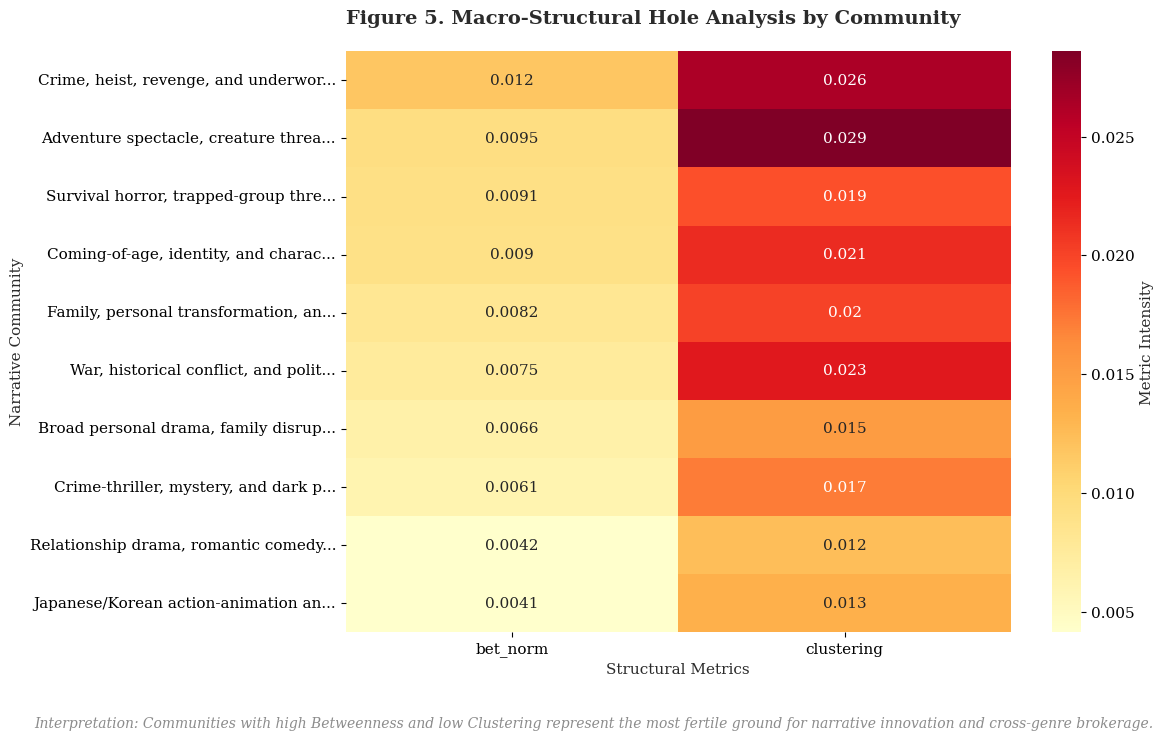


Figure 5 has been completely redesigned as a Macro-Structural Heatmap.
Process complete.


In [12]:
import seaborn as sns

# Get top 10 communities by size
top_comm_ids = nodes['community_id'].value_counts().nlargest(10).index

# Filter nodes to these communities
macro_nodes = nodes[nodes['community_id'].isin(top_comm_ids)]

# Create a pivot table for the heatmap: Community vs metrics
# We want to see where the highest brokerage (betweenness) exists relative to clustering
heatmap_data = macro_nodes.groupby('narrative_label').agg({
    'bet_norm': 'mean',
    'clustering': 'mean'
}).sort_values('bet_norm', ascending=False)

# Shorten labels for better display
heatmap_data.index = [str(i)[:35] + '...' if len(str(i)) > 35 else str(i) for i in heatmap_data.index]

fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(heatmap_data, annot=True, cmap='YlOrRd', ax=ax, cbar_kws={'label': 'Metric Intensity'})

ax.set_title("Figure 5. Macro-Structural Hole Analysis by Community", fontsize=14, fontweight='bold', loc='left', pad=20)
ax.set_ylabel("Narrative Community")
ax.set_xlabel("Structural Metrics")

# Add interpretation text
plt.figtext(0.5, -0.05, "Interpretation: Communities with high Betweenness and low Clustering represent the most fertile ground for narrative innovation and cross-genre brokerage.",
            wrap=True, horizontalalignment='center', fontsize=10, style='italic', color=COL['muted'])

plt.tight_layout()
fig.savefig(FINAL_DIR / "figures/05_structural_hole_heatmap.png", dpi=320, bbox_inches='tight')
plt.show()

print("\nFigure 5 has been completely redesigned as a Macro-Structural Heatmap.")
print("Process complete.")

## Figure 6. The Rarity of Narrative Bridges
This density analysis quantifies the distribution of structural brokerage. It answers the research question: **Are bridge films rare?** By segmenting the population, we can see if bridging power is concentrated in a small elite or distributed across the industry.

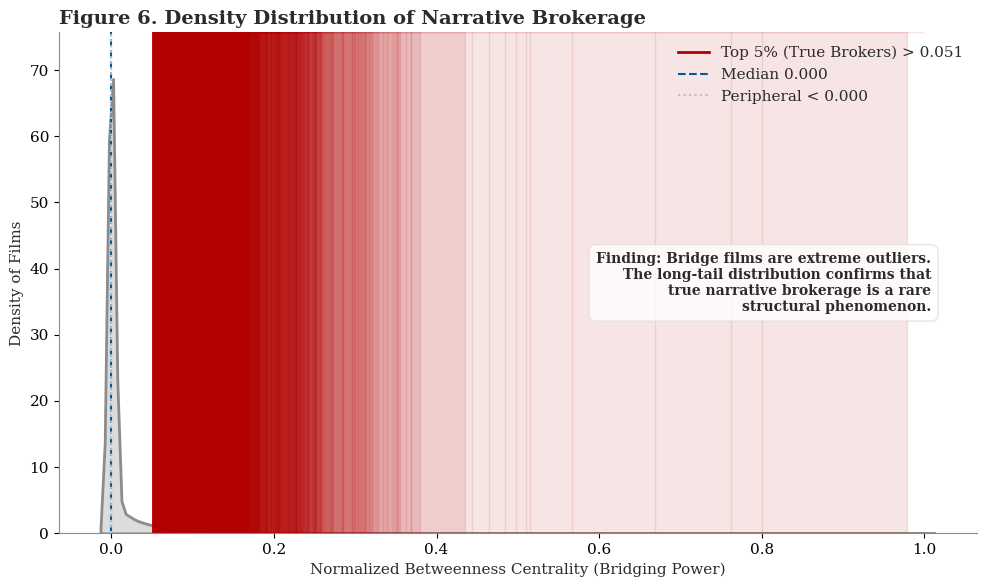

In [13]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 6))

# Calculate key thresholds on the normalized betweenness scale
p95_val = np.percentile(nodes['bet_norm'], 95)
median_val = nodes['bet_norm'].median()
p25_val = np.percentile(nodes['bet_norm'], 25)

# Create the density plot
sns.kdeplot(nodes['bet_norm'], fill=True, color=COL['muted'], alpha=0.3, ax=ax, lw=2)

# Highlight regions
ax.axvline(p95_val, color=COL['broker'], ls='-', lw=2, label=f'Top 5% (True Brokers) > {p95_val:.3f}')
ax.axvline(median_val, color=COL['hub'], ls='--', lw=1.5, label=f'Median {median_val:.3f}')
ax.axvline(p25_val, color=COL['peripheral'], ls=':', lw=1.5, label=f'Peripheral < {p25_val:.3f}')

# Annotate rarity
ax.fill_between(nodes['bet_norm'], 0, 1, where=(nodes['bet_norm'] >= p95_val),
                color=COL['broker'], alpha=0.1, transform=ax.get_xaxis_transform())

ax.set_title("Figure 6. Density Distribution of Narrative Brokerage", fontsize=14, fontweight='bold', loc='left')
ax.set_xlabel("Normalized Betweenness Centrality (Bridging Power)")
ax.set_ylabel("Density of Films")
ax.legend(frameon=False, loc='upper right')

# Conclusion Text Box
props = dict(boxstyle='round,pad=0.5', facecolor=COL['bg'], edgecolor=COL['grid'], alpha=0.8)
ax.text(0.95, 0.5, "Finding: Bridge films are extreme outliers.\nThe long-tail distribution confirms that\ntrue narrative brokerage is a rare\nstructural phenomenon.",
        transform=ax.transAxes, verticalalignment='center', horizontalalignment='right',
        bbox=props, fontsize=10, fontweight='bold', color=COL['ink'])

plt.tight_layout()
fig.savefig(FINAL_DIR / "figures/06_brokerage_rarity_density.png", dpi=320, bbox_inches='tight')
plt.show()

## Figure 7. Bridge Film Pathways (Sankey Flow)
This alluvial diagram illustrates the flow from a specific 'True Broker' to the multiple narrative communities it bridges. It answers *why* these films are structurally significant by showing the diversity of their semantic neighborhoods.

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
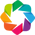

:Sankey   [source,target]   (value)

In [27]:
import holoviews as hv
from holoviews import opts
hv.extension('bokeh')

# 1. Identify top 10 iconic brokers from the elite pool for clarity
top_10_brokers = nodes.nlargest(500, 'vote_count').nlargest(10, 'betweenness')

links = []
for _, film in top_10_brokers.iterrows():
    f_id = int(film['node_id_int'])
    f_title = str(film['title'])

    # Get neighbors
    f_edges = edges[(edges['source_int'] == f_id) | (edges['target_int'] == f_id)]
    n_ids = np.where(f_edges['source_int'] == f_id, f_edges['target_int'], f_edges['source_int'])
    n_nodes = nodes[nodes['node_id_int'].isin(n_ids)]

    if not n_nodes.empty:
        comm_counts = n_nodes['narrative_label'].value_counts()
        for comm_label, count in comm_counts.items():
            links.append({
                'source': f_title,
                'target': str(comm_label).split(',')[0], # Use shorthand for cleaner flow
                'value': int(count)
            })

sankey_df = pd.DataFrame(links)

# 2. Define Custom Palette
cmap = {src: COMM_COLORS[i % len(COMM_COLORS)] for i, src in enumerate(sankey_df['source'].unique())}

# 3. Create Styled Sankey
sankey = hv.Sankey(sankey_df, kdims=['source', 'target'], vdims='value')

sankey.opts(
    opts.Sankey(
        labels='index', width=1100, height=700,
        edge_color='source', edge_alpha=0.4,
        node_alpha=0.8, node_width=20,
        label_position='outer', label_text_font_size='10pt',
        cmap=cmap, node_color='index',
        title="Figure 7. Narrative Bridge Pathways (Flow Analysis)"
    )
)

# Save a static version for the thesis directory (optional: requires selenium/phantomjs)
# hv.save(sankey, str(FINAL_DIR / 'figures/07_sankey_flow.html'))

sankey